In [19]:
import pandas as pd
import numpy as np

In [20]:
df = pd.read_csv('/content/train.csv')

df.shape

(120000, 3)

In [21]:
df.columns.tolist()


['Class Index', 'Title', 'Description']

In [22]:
df.head()

,Class Index,Title,Description
0,3,Wall St. Bears Claw Back Into the Black (Reuters),"Reuters - Short-sellers, Wall Street's dwindli..."
1,3,Carlyle Looks Toward Commercial Aerospace (Reu...,Reuters - Private investment firm Carlyle Grou...
2,3,Oil and Economy Cloud Stocks' Outlook (Reuters),Reuters - Soaring crude prices plus worries\ab...
3,3,Iraq Halts Oil Exports from Main Southern Pipe...,Reuters - Authorities have halted oil export\f...
4,3,"Oil prices soar to all-time record, posing new...","AFP - Tearaway world oil prices, toppling reco..."


In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 3 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   Class Index  120000 non-null  int64 
 1   Title        120000 non-null  object
 2   Description  120000 non-null  object
dtypes: int64(1), object(2)
memory usage: 2.7+ MB


In [24]:
df.isna().sum()

,0
Class Index,0
Title,0
Description,0


In [25]:
df.duplicated().sum()


np.int64(0)

In [26]:
df['Class Index'].value_counts()

,count
Class Index,
3,30000
4,30000
2,30000
1,30000


In [27]:
df['text'] = df['Title'] + ' ' + df['Description']

class_names = {1: 'World', 2: 'Sports', 3: 'Business', 4: 'Sci/Tech'}
df['label_name'] = df['Class Index'].map(class_names)

print(df[['text', 'Class Index', 'label_name']].head())
print(df['label_name'].value_counts())
print("Mean number word", df['text'].str.split().str.len().mean())

                                                text  Class Index label_name
0  Wall St. Bears Claw Back Into the Black (Reute...            3   Business
1  Carlyle Looks Toward Commercial Aerospace (Reu...            3   Business
2  Oil and Economy Cloud Stocks' Outlook (Reuters...            3   Business
3  Iraq Halts Oil Exports from Main Southern Pipe...            3   Business
4  Oil prices soar to all-time record, posing new...            3   Business
label_name
Business    30000
Sci/Tech    30000
Sports      30000
World       30000
Name: count, dtype: int64
Mean number word 37.84461666666667


In [28]:
import re
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

def clean(t):
    t = t.lower().replace('\\', ' ')
    t = re.sub(r'[^a-z\s]', ' ', t)
    return re.sub(r'\s+', ' ', t).strip()

df['clean_text'] = df['text'].apply(clean)

y = df['Class Index'] - 1

X_train, X_test, y_train, y_test = train_test_split(
    df['clean_text'], y, test_size=0.2, random_state=42, stratify=y)

vec = TfidfVectorizer(stop_words='english', max_features=5000, dtype=np.float32)
X_train_vec = vec.fit_transform(X_train).toarray()
X_test_vec = vec.transform(X_test).toarray()

print(X_train_vec.shape, X_test_vec.shape)
print(y_train.value_counts())

(96000, 5000) (24000, 5000)
Class Index
1    24000
3    24000
0    24000
2    24000
Name: count, dtype: int64


In [29]:
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    layers.Input(shape=(5000,)),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(4, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
model.summary()

early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=2, restore_best_weights=True)

history = model.fit(X_train_vec, y_train,
                    validation_split=0.1,
                    epochs=15, batch_size=128,
                    callbacks=[early_stop])

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 256)            │     1,280,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,313,668 (5.01 MB)

 Trainable params: 1,313,668 (5.01 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
675/675 ━━━━━━━━━━━━━━━━━━━━ 22s 30ms/step - accuracy: 0.8758 - loss: 0.3832 - val_accuracy: 0.9096 - val_loss: 0.2739
Epoch 2/15
675/675 ━━━━━━━━━━━━━━━━━━━━ 21s 31ms/step - accuracy: 0.9210 - loss: 0.2347 - val_accuracy: 0.9103 - val_loss: 0.2707
Epoch 3/15
675/675 ━━━━━━━━━━━━━━━━━━━━ 42s 32ms/step - accuracy: 0.9358 - loss: 0.1909 - val_accuracy: 0.9085 - val_loss: 0.2844
Epoch 4/15
675/675 ━━━━━━━━━━━━━━━━━━━━ 20s 29ms/step - accuracy: 0.9465 - loss: 0.1558 - val_accuracy: 0.9062 - val_loss: 0.2945


750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step
Test Accuracy: 0.912
              precision    recall  f1-score   support

       World       0.93      0.90      0.91      6000
      Sports       0.95      0.98      0.96      6000
    Business       0.87      0.90      0.88      6000
    Sci/Tech       0.90      0.87      0.89      6000

    accuracy                           0.91     24000
   macro avg       0.91      0.91      0.91     24000
weighted avg       0.91      0.91      0.91     24000

[[5393  194  274  139]
 [  67 5865   40   28]
 [ 178   50 5383  389]
 [ 173   68  512 5247]]


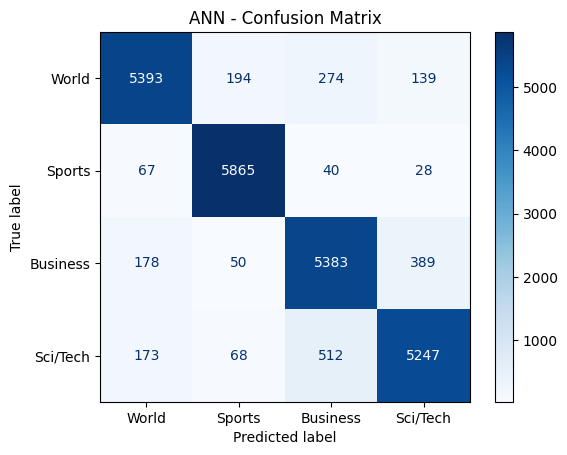

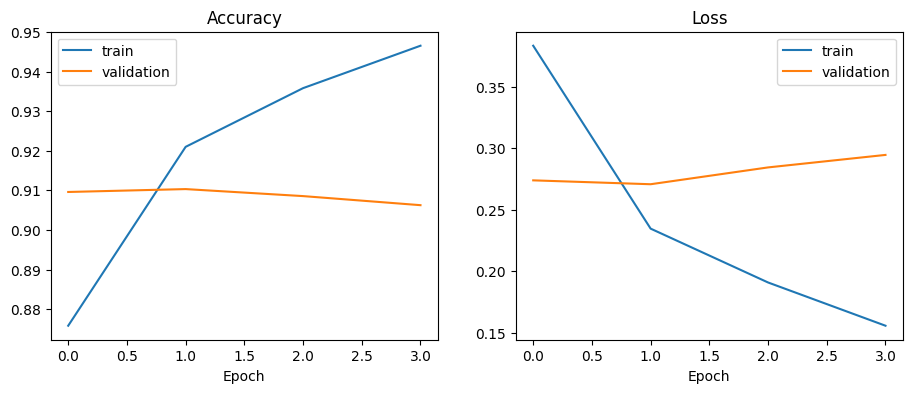

In [30]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

pred = model.predict(X_test_vec).argmax(axis=1)
names = ['World', 'Sports', 'Business', 'Sci/Tech']

print("Test Accuracy:", accuracy_score(y_test, pred))
print(classification_report(y_test, pred, target_names=names))

cm = confusion_matrix(y_test, pred)
print(cm)
ConfusionMatrixDisplay(cm, display_labels=names).plot(cmap='Blues')
plt.title('ANN - Confusion Matrix')
plt.show()

# Training vs Validation curve
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history.history['accuracy'], label='train')
ax[0].plot(history.history['val_accuracy'], label='validation')
ax[0].set_title('Accuracy'); ax[0].set_xlabel('Epoch'); ax[0].legend()
ax[1].plot(history.history['loss'], label='train')
ax[1].plot(history.history['val_loss'], label='validation')
ax[1].set_title('Loss'); ax[1].set_xlabel('Epoch'); ax[1].legend()
plt.show()

## Evaluation and Analysis

The ANN (5000 → 256 → 128 → 4, with dropout) achieved a test accuracy of **91.5%** on 24,000 unseen articles (macro F1 ≈ 0.91). Sports was classified best (F1 0.96), while Business and Sci/Tech were weakest (F1 0.89).

**Factors affecting accuracy:**

- **Class overlap:** Most errors are between Business and Sci/Tech (512 and 339 articles), since both cover company and technology news with shared vocabulary.
- **Overfitting:** Training accuracy rose to about 0.95 while validation accuracy stayed near 0.91; dropout and early stopping limited this.
- **Bag-of-words features:** TF-IDF (5,000 features) ignores word order and context, and the articles are short (about 38 words on average).

**Improvement:** use word embeddings with an LSTM/CNN, or a pre-trained model such as BERT.